# 04 · H2: какие алгоритмы восстанавливают разные зависимости риска?

**H2:** при известных нелинейностях и взаимодействиях между факторами риска более гибкие модели могут иметь преимущество перед фиксированной PLCOm2012 и обычной Logistic Regression.

Сравниваем S0–S3 **на одинаковом пуле пациентов и общих индексах разбиения**. Для каждого сценария алгоритмы оптимизируются **только на train** через 3-fold CV. Порог выбираем на validation при Specificity ≥90%; test открываем только для финальной оценки. Первичная метрика сравнения — pAUC в диапазоне FPR≤0,10; дополнительно Recall, фактическая специфичность, ROC AUC, AP, Brier и ошибка восстановления **известной истинной вероятности** (risk MSE).

**Научное ограничение:** S1–S2 — гибриды PLCO с мужскими коэффициентами Remen et al. (не полные модели, не клиническая валидация). S3 содержит наши экспериментальные β. Подробное происхождение см. `references/literature.md`.

**Важно:** 4 сценария × несколько моделей × один seed дают предварительные результаты. Устойчивые выводы требуют H4 (повторных генераций). Не меняйте сценарии, поисковые пространства или пороги после просмотра test.

## 1. Импорты и среда

In [3]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'src' / 'data_generation.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Запускайте Jupyter из корня репозитория или notebooks/')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_generation import generate_baseline
from src.h2_generation import SCENARIOS, apply_h2_scenario, csi_index
from src.preprocessing import FEATURE_COLUMNS

print('Проект:', PROJECT_ROOT)
print('Python:', sys.version.split()[0])
import json
import time
import warnings
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, make_scorer
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from src.plco import plco_risk
from src.preprocessing import split_dataset, make_preprocessor
from src.evaluation import evaluate_binary, select_threshold_at_specificity

import sklearn, xgboost
print('scikit-learn:', sklearn.__version__, '| xgboost:', xgboost.__version__)

Проект: /Users/dyadyundanil/Documents/lung-cancer-ml-study
Python: 3.11.11
scikit-learn: 1.9.1 | xgboost: 3.2.0


## 2. Настройки до анализа test

`QUICK_RUN=True` нужен только для отладки. Для итогового коммита используем **полный режим**, сохранив все результаты. Поиск по 6 конфигурациям и 3 фолдам для 4 алгоритмов на каждом сценарии может занимать заметное время. Параметры поиска фиксируем **до оценки test**.

In [6]:
QUICK_RUN = False
N = 12_000 if QUICK_RUN else 50_000
N_ITER = 2 if QUICK_RUN else 6
DATA_SEED = 42
OUTCOME_SEED = 2026
SPLIT_SEED = 123
CV_SEED = 1729
MODEL_SEED = 2026
MIN_SPECIFICITY = 0.90
N_FOLDS = 3
SEARCH_N_JOBS = 1
ESTIMATOR_N_JOBS = 1

baseline = generate_baseline(N, seed=DATA_SEED)
datasets = {s: apply_h2_scenario(baseline, scenario=s, outcome_seed=OUTCOME_SEED)
            for s in SCENARIOS}
reference_split = split_dataset(datasets['S0'], seed=SPLIT_SEED)
train_index, val_index, test_index = (
    reference_split.X_train.index, reference_split.X_val.index,
    reference_split.X_test.index,
)
assert not set(train_index) & set(val_index)
assert not set(train_index) & set(test_index)
assert not set(val_index) & set(test_index)
assert all(np.array_equal(datasets[s][list(FEATURE_COLUMNS)],
                                  datasets['S0'][list(FEATURE_COLUMNS)]) for s in SCENARIOS)
print('N:', N, 'разбиение:', len(train_index), len(val_index), len(test_index))
for s, df in datasets.items():
    print(s, 'положительных (train/val/test):',
          [int(df.loc[idx, 'y'].sum()) for idx in (train_index, val_index, test_index)])

N: 50000 разбиение: 30000 10000 10000
S0 положительных (train/val/test): [251, 84, 83]
S1 положительных (train/val/test): [239, 79, 79]
S2 положительных (train/val/test): [233, 87, 86]
S3 положительных (train/val/test): [248, 79, 83]


## 3. Модели и пространства гиперпараметров

Воспроизводим принципы H1. Препроцессор находится **внутри Pipeline**, поэтому в CV каждый раз обучается только на тренировочном фолде. PLCOm2012 не обучается и не перенастраивается; «истинная функция» используется **только для контрольных метрик**, а не как ML-признак.

In [9]:
def make_models():
    def pipeline(model):
        return Pipeline([('preprocessor', make_preprocessor()), ('model', model)])
    return {
        'Logistic Regression': pipeline(LogisticRegression(max_iter=1000, random_state=MODEL_SEED)),
        'Random Forest': pipeline(RandomForestClassifier(random_state=MODEL_SEED, n_jobs=ESTIMATOR_N_JOBS)),
        'XGBoost': pipeline(XGBClassifier(objective='binary:logistic', eval_metric='logloss',
                                          tree_method='hist', n_jobs=ESTIMATOR_N_JOBS,
                                          random_state=MODEL_SEED)),
        'MLP': pipeline(MLPClassifier(random_state=MODEL_SEED)),
    }

SEARCH_SPACES = {
    'Logistic Regression': {'model__C': [0.01, 0.03, 0.1, 0.3, 3.0, 10.0, 30.0]},
    'Random Forest': {
        'model__n_estimators': [120, 220, 320], 'model__max_depth': [None, 8, 14],
        'model__min_samples_leaf': [2, 6, 15], 'model__max_features': ['sqrt', 0.7],
    },
    'XGBoost': {
        'model__n_estimators': [100, 200, 320], 'model__max_depth': [2, 3, 5],
        'model__learning_rate': [0.02, 0.05, 0.1],
        'model__min_child_weight': [1, 5, 15], 'model__subsample': [0.8, 1.0],
        'model__colsample_bytree': [0.8, 1.0],
    },
    'MLP': {
        'model__hidden_layer_sizes': [(24,), (48,), (32, 16)],
        'model__alpha': [0.0001, 0.001, 0.01, 0.1],
        'model__learning_rate_init': [0.0005, 0.001, 0.003],
    },
}
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=CV_SEED)
pauc_scorer = make_scorer(roc_auc_score, response_method='predict_proba', max_fpr=0.10)

## 4. Настройка моделей и выбор порога (test пока не используем)

В каждом сценарии сначала сравниваем исходную модель и лучший результат RandomizedSearchCV на train-CV (по pAUC); берём исходную, если CV-поиск не улучшил оценку. Затем на validation подбираем порог. Предупреждения MLP `ConvergenceWarning` показывают возможную неполную сходимость отдельных конфигураций и должны быть отмечены в отчёте.

In [12]:
experiments = {}
search_rows = []
for si, scenario in enumerate(SCENARIOS):
    df = datasets[scenario]
    X_train = df.loc[train_index, list(FEATURE_COLUMNS)]
    y_train = df.loc[train_index, 'y']
    X_val = df.loc[val_index, list(FEATURE_COLUMNS)]
    y_val = df.loc[val_index, 'y']
    experiments[scenario] = {}
    print(f'\n=== {scenario} ===')
    for mi, (name, base_model) in enumerate(make_models().items()):
        started = time.perf_counter()
        scores = cross_val_score(base_model, X_train, y_train, cv=cv, scoring=pauc_scorer,
                                 n_jobs=SEARCH_N_JOBS, error_score='raise')
        search = RandomizedSearchCV(
            base_model, SEARCH_SPACES[name], n_iter=N_ITER, scoring=pauc_scorer,
            cv=cv, n_jobs=SEARCH_N_JOBS, random_state=MODEL_SEED + si*10 + mi,
            refit=True, error_score='raise',
        )
        search.fit(X_train, y_train)
        keep_default = float(scores.mean()) >= float(search.best_score_)
        if keep_default:
            model = base_model.fit(X_train, y_train)
            params = {}
        else:
            model = search.best_estimator_
            params = search.best_params_
        p_val = model.predict_proba(X_val)[:, 1]
        threshold = select_threshold_at_specificity(y_val, p_val,
                                                      min_specificity=MIN_SPECIFICITY)
        experiments[scenario][name] = {'model': model, 'threshold': float(threshold),
                                        'params': params}
        search_rows.append({
            'scenario': scenario, 'model': name,
            'cv_pauc_default': float(scores.mean()),
            'cv_pauc_search': float(search.best_score_),
            'cv_pauc_selected': float(max(scores.mean(), search.best_score_)),
            'selected': 'default' if keep_default else 'tuned',
            'threshold': float(threshold), 'params': params,
            'fit_seconds': time.perf_counter() - started,
        })
        print(f'{name}: CV pAUC {scores.mean():.4f} -> '
              f'{max(scores.mean(),search.best_score_):.4f}; '
              f'{"исходная" if keep_default else "настроенная"}')
search_table = pd.DataFrame(search_rows)
display(search_table.drop(columns='params').round(4))


=== S0 ===
Logistic Regression: CV pAUC 0.6308 -> 0.6308; исходная
Random Forest: CV pAUC 0.5993 -> 0.6366; настроенная
XGBoost: CV pAUC 0.5950 -> 0.6377; настроенная


/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  war

MLP: CV pAUC 0.6085 -> 0.6379; настроенная

=== S1 ===
Logistic Regression: CV pAUC 0.6081 -> 0.6117; настроенная
Random Forest: CV pAUC 0.5650 -> 0.5985; настроенная
XGBoost: CV pAUC 0.5429 -> 0.5987; настроенная


/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  war

MLP: CV pAUC 0.5649 -> 0.5956; настроенная

=== S2 ===
Logistic Regression: CV pAUC 0.5897 -> 0.5897; исходная
Random Forest: CV pAUC 0.5586 -> 0.5618; настроенная
XGBoost: CV pAUC 0.5383 -> 0.5842; настроенная


/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  war

MLP: CV pAUC 0.5540 -> 0.5858; настроенная

=== S3 ===
Logistic Regression: CV pAUC 0.6219 -> 0.6225; настроенная
Random Forest: CV pAUC 0.5776 -> 0.6193; настроенная
XGBoost: CV pAUC 0.5769 -> 0.6203; настроенная


/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/lung-cancer-ml/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  war

MLP: CV pAUC 0.5930 -> 0.6301; настроенная


,scenario,model,cv_pauc_default,cv_pauc_search,cv_pauc_selected,selected,threshold,fit_seconds
0,S0,Logistic Regression,0.6308,0.6301,0.6308,default,0.0157,0.6028
1,S0,Random Forest,0.5993,0.6366,0.6366,tuned,0.0206,48.6475
2,S0,XGBoost,0.5950,0.6377,0.6377,tuned,0.0216,4.0440
3,S0,MLP,0.6085,0.6379,0.6379,tuned,0.0254,61.0838
4,S1,Logistic Regression,0.6081,0.6117,0.6117,tuned,0.0167,0.5707
5,S1,Random Forest,0.5650,0.5985,0.5985,tuned,0.0162,55.9394
6,S1,XGBoost,0.5429,0.5987,0.5987,tuned,0.0176,4.0285
7,S1,MLP,0.5649,0.5956,0.5956,tuned,0.0179,60.0567
8,S2,Logistic Regression,0.5897,0.5896,0.5897,default,0.0156,0.5797
9,S2,Random Forest,0.5586,0.5618,0.5618,tuned,0.0187,64.8912


## 5. Окончательная оценка на test

Теперь применяем *зафиксированные* модели и пороги к test. PLCOm2012 — фиксированный компаратор. `Истинная функция` даёт вероятности из генератора и нужна для оценки достижимого качества, **не участвует в конкурсе обучаемых моделей**. Добавляем `risk_mse` — MSE прогнозируемой вероятности относительно истинной $p_{true}$; это особенно информативно на синтетических данных.

In [15]:
test_rows = []
for scenario in SCENARIOS:
    df = datasets[scenario]
    X = df.loc[test_index, list(FEATURE_COLUMNS)]
    y = df.loc[test_index, 'y']
    true_risk = df.loc[test_index, 'risk'].to_numpy()
    # Порог для PLCO также устанавливается только на validation.
    p_plco_val = datasets[scenario].loc[val_index, list(FEATURE_COLUMNS)].apply(plco_risk, axis=1).to_numpy()
    t_plco = select_threshold_at_specificity(df.loc[val_index,'y'], p_plco_val,
                                             min_specificity=MIN_SPECIFICITY)
    candidates = [('PLCOm2012', X.apply(plco_risk, axis=1).to_numpy(), t_plco)]
    candidates.extend((name, entry['model'].predict_proba(X)[:, 1], entry['threshold'])
                      for name, entry in experiments[scenario].items())
    for name, probs, threshold in candidates:
        scores = evaluate_binary(y, probs, threshold=threshold)
        test_rows.append({'scenario':scenario, 'model':name,
                          'recall': scores['recall'], 'specificity':scores['specificity'],
                          'pauc_std':scores['pauc_standardized_fpr_0_10'],
                          'roc_auc':scores['roc_auc'],
                          'ap':scores['average_precision'],
                          'brier':scores['brier_score'],
                          'risk_mse':float(np.mean((probs - true_risk)**2)),
                          'tp':scores['tp'],'fp':scores['fp'],
                          'positives':scores['positives'], 'threshold':threshold})
report = pd.DataFrame(test_rows)
display(report.set_index(['scenario','model']).round(5))

recall  specificity  pauc_std  roc_auc  \
scenario model                                                          
S0       PLCOm2012            0.56627      0.89523   0.66259  0.87273   
         Logistic Regression  0.53012      0.89755   0.64510  0.83506   
         Random Forest        0.53012      0.89221   0.64845  0.84946   
         XGBoost              0.51807      0.89604   0.64501  0.86965   
         MLP                  0.54217      0.90057   0.64290  0.86513   
S1       PLCOm2012            0.44304      0.89547   0.62338  0.75761   
         Logistic Regression  0.45570      0.90152   0.62165  0.77031   
         Random Forest        0.44304      0.89578   0.62783  0.76027   
         XGBoost              0.40506      0.89900   0.62320  0.76060   
         MLP                  0.41772      0.90263   0.60685  0.78269   
S2       PLCOm2012            0.34884      0.89510   0.59079  0.71004   
         Logistic Regression  0.36047      0.89439   0.57841  0.74420   
         Random Forest        0.30233      0.89540   0.56049  0.67110   
         XGBoost              0.31395      0.89419   0.56391  0.71034   
         MLP                  0.32558      0.89651   0.57411  0.73742   
S3       PLCOm2012            0.53012      0.89523   0.65632  0.86082   
         Logistic Regression  0.50602      0.89705   0.63423  0.82699   
         Random Forest        0.54217      0.89442   0.63617  0.84113   
         XGBoost              0.40964      0.89765   0.60873  0.84616   
         MLP                  0.51807      0.89785   0.62621  0.85223   

                                   ap    brier  risk_mse  tp    fp  positives  \
scenario model                                                                  
S0       PLCOm2012            0.07129  0.00797   0.00000  47  1039         83   
         Logistic Regression  0.06442  0.00802   0.00014  44  1016         83   
         Random Forest        0.05317  0.00803   0.00007  44  1069         83   
         XGBoost              0.06270  0.00801   0.00006  43  1031         83   
         MLP                  0.05510  0.00803   0.00005  45   986         83   
S1       PLCOm2012            0.04678  0.00773   0.00007  35  1037         79   
         Logistic Regression  0.04760  0.00771   0.00005  36   977         79   
         Random Forest        0.05516  0.00772   0.00007  35  1034         79   
         XGBoost              0.04506  0.00771   0.00006  32  1002         79   
         MLP                  0.04033  0.00772   0.00005  33   966         79   
S2       PLCOm2012            0.03817  0.00846   0.00005  30  1040         86   
         Logistic Regression  0.04791  0.00841   0.00003  31  1047         86   
         Random Forest        0.03265  0.00852   0.00013  26  1037         86   
         XGBoost              0.03435  0.00846   0.00004  27  1049         86   
         MLP                  0.03421  0.00845   0.00003  28  1026         86   
S3       PLCOm2012            0.06929  0.00799   0.00001  44  1039         83   
         Logistic Regression  0.06629  0.00803   0.00015  42  1021         83   
         Random Forest        0.06073  0.00804   0.00007  45  1047         83   
         XGBoost              0.05865  0.00808   0.00006  34  1015         83   
         MLP                  0.06134  0.00804   0.00004  43  1013         83   

                              threshold  
scenario model                           
S0       PLCOm2012              0.02240  
         Logistic Regression    0.01568  
         Random Forest          0.02064  
         XGBoost                0.02157  
         MLP                    0.02542  
S1       PLCOm2012              0.02258  
         Logistic Regression    0.01675  
         Random Forest          0.01617  
         XGBoost                0.01764  
         MLP                    0.01791  
S2       PLCOm2012              0.02259  
         Logistic Regression    0.01559  
         Random Forest          0.01873  
         XG

**Вывод.** Подбор гиперпараметров улучшил кросс-валидационную pAUC большинства моделей во всех четырёх сценариях. Наиболее заметный прирост наблюдается у Random Forest, XGBoost и MLP, тогда как Logistic Regression демонстрирует минимальные изменения.

Это подтверждает важность настройки более сложных алгоритмов. Однако улучшение на кросс-валидации не гарантирует превосходства на независимой тестовой выборке.

## 6. Сравнение по сценариям и графики

Ниже представлены **описательные** лидеры по pAUC на одном наборе генераций. Тот же test использован для сравнения всех моделей; если мы выберем победителя по test, его метрики будут оптимистично смещены. Повторные генерации H4 нужны для проверки устойчивости.

**Вывод.** Среди обучаемых моделей по pAUC Random Forest занимает первое место в сценариях S0, S1 и S3, тогда как в S2 лидирует Logistic Regression.

Полученные результаты не подтверждают предположение о безусловном преимуществе нелинейных алгоритмов. При этом смена лидера между сценариями показывает, что эффективность модели зависит от структуры зависимости между признаками и риском заболевания.

Исследовательские лидеры среди ML по pAUC (один seed):


,model,pauc_std,recall,specificity,risk_mse
scenario,,,,,
S0,Random Forest,0.64845,0.53012,0.89221,0.00007
S3,Random Forest,0.63617,0.54217,0.89442,0.00007
S1,Random Forest,0.62783,0.44304,0.89578,0.00007
S2,Logistic Regression,0.57841,0.36047,0.89439,0.00003


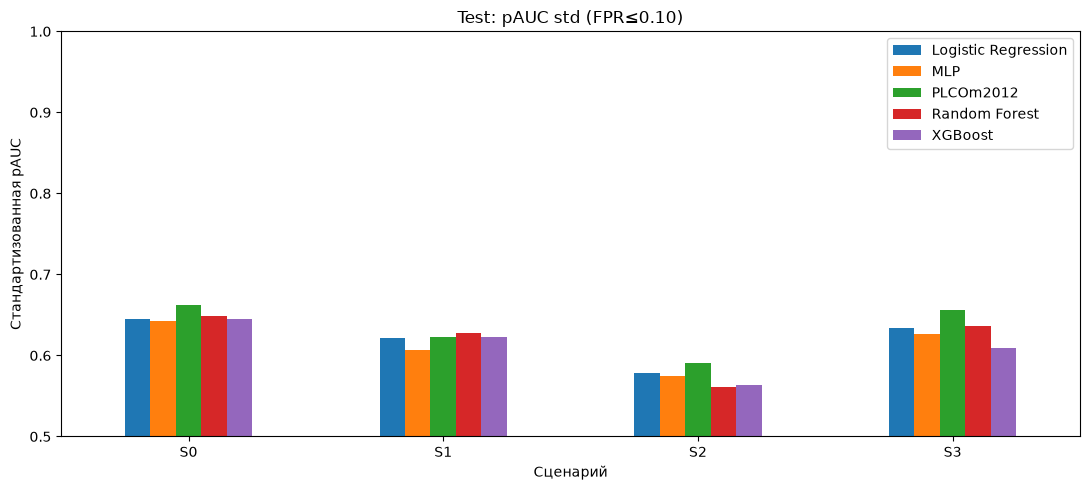

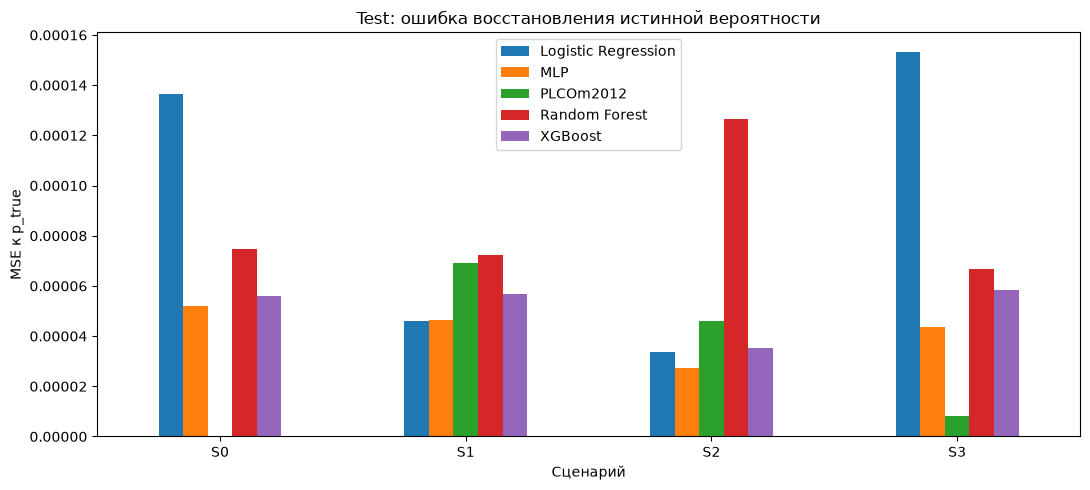

In [18]:
ml_only = report.query("model != 'PLCOm2012'")
winners = (ml_only.sort_values('pauc_std', ascending=False)
           .drop_duplicates('scenario')[['scenario','model','pauc_std','recall','specificity','risk_mse']])
print('Исследовательские лидеры среди ML по pAUC (один seed):')
display(winners.set_index('scenario').round(5))

pivot = report.pivot(index='scenario', columns='model', values='pauc_std')
ax = pivot.plot(kind='bar', figsize=(11,5), ylim=(0.5, 1), rot=0, title='Test: pAUC std (FPR≤0.10)')
ax.set(ylabel='Стандартизованная pAUC', xlabel='Сценарий'); ax.legend(loc='best')
plt.tight_layout(); plt.show()

pivot2 = report.pivot(index='scenario', columns='model', values='risk_mse')
ax = pivot2.plot(kind='bar', figsize=(11,5), rot=0,
                 title='Test: ошибка восстановления истинной вероятности')
ax.set(ylabel='MSE к p_true', xlabel='Сценарий'); ax.legend(loc='best')
plt.tight_layout(); plt.show()

### Вывод 1: Анализ метрики pAUC (качество ранжирования)

**Вывод.** PLCOm2012 сохраняет наибольшую pAUC в сценариях S0 (0,6626), S2 (0,5908) и S3 (0,6563). В S1 небольшое преимущество получает Random Forest (0,6278 против 0,6234 у PLCOm2012).

Среди обучаемых моделей Random Forest лидирует в трёх сценариях из четырёх, тогда как в S2 лучший результат показывает Logistic Regression.

Следовательно, преимущество нелинейных алгоритмов не является универсальным и зависит от механизма генерации риска.


### Вывод 2: Анализ ошибки MSE (калибровка вероятностей)

**Вывод.** В контрольном сценарии S0 ошибка PLCOm2012 относительно истинной вероятности равна нулю, поскольку её формула непосредственно использована в генераторе.

В S1 и S2 после изменения исходного механизма риска обучаемые модели способны приблизиться к новым истинным вероятностям. В частности, Logistic Regression и MLP демонстрируют меньшую MSE, чем фиксированная PLCOm2012.

В S3 ошибка PLCOm2012 остаётся очень небольшой, поскольку добавленные взаимодействия сравнительно слабо изменяют исходный логит. Результаты показывают, что способность восстанавливать истинные вероятности не всегда совпадает с качеством ранжирования пациентов по pAUC.

## 7. Сохранение результатов и правил эксперимента

In [21]:
out = PROJECT_ROOT / 'results'
out.mkdir(exist_ok=True)
report.to_csv(out/'h2_test_metrics.csv', index=False)
search_table.to_csv(out/'h2_tuning_summary.csv', index=False)
config = {
    'n': N, 'quick_run': QUICK_RUN, 'data_seed': DATA_SEED,
    'outcome_seed': OUTCOME_SEED, 'split_seed': SPLIT_SEED,
    'cv_seed': CV_SEED, 'model_seed': MODEL_SEED,
    'n_iter': N_ITER, 'n_folds': N_FOLDS,
    'min_specificity_validation': MIN_SPECIFICITY,
    'selected_params': {s: {name: entry['params'] for name, entry in variants.items()}
                        for s, variants in experiments.items()},
}
(out/'h2_selected_params.json').write_text(
    json.dumps(config, indent=2, ensure_ascii=False), encoding='utf-8')
print('Сохранено:', *(str(p.name) for p in (out/'h2_test_metrics.csv',
                                      out/'h2_tuning_summary.csv',
                                      out/'h2_selected_params.json')))

Сохранено: h2_test_metrics.csv h2_tuning_summary.csv h2_selected_params.json


## 8.Промежуточный вывод по гипотезе H2

**Статус: гипотеза H2 не получила убедительного подтверждения в проведённом эксперименте.**

Разработаны четыре сценария генерации синтетических данных, включающие исходную модель PLCOm2012, альтернативные зависимости характеристик курения и дополнительные взаимодействия факторов риска.

Результаты показали, что качество алгоритмов зависит от механизма генерации данных. Однако нелинейные модели Random Forest, XGBoost и MLP не продемонстрировали систематического превосходства над Logistic Regression и PLCOm2012.

Вместе с тем при изменении исходных зависимостей отдельные обучаемые модели точнее восстанавливают истинные вероятности, чем фиксированная PLCOm2012. Это свидетельствует об их способности адаптироваться к альтернативным механизмам формирования риска.

**Таким образом, универсальное преимущество нелинейных алгоритмов не установлено.** Вывод ограничен рассмотренными сценариями, одним случайным запуском и небольшим числом положительных исходов в тестовых выборках.